In [1]:

# Install required libraries
!pip install -q medmnist

# Import libraries
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import transforms

import medmnist
from medmnist import BreastMNIST

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cu130
GPU available: True


In [2]:
# Load training, validation and testing datasets

train_dataset = BreastMNIST(
    split='train',
    download=True,
    transform=transforms.ToTensor()
)

val_dataset = BreastMNIST(
    split='val',
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = BreastMNIST(
    split='test',
    download=True,
    transform=transforms.ToTensor()
)

# Check dataset sizes
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 560k/560k [00:00<00:00, 4.47MB/s]

Training samples: 546
Validation samples: 78
Testing samples: 156


In [7]:
# Check training class distribution
labels = [int(label[0]) for _, label in train_dataset]

unique, counts = np.unique(labels, return_counts=True)

print("\nTraining class distribution:")
for label, count in zip(unique, counts):
    print(f"Class {label}: {count} images")


Training class distribution:
Class 0: 147 images
Class 1: 399 images


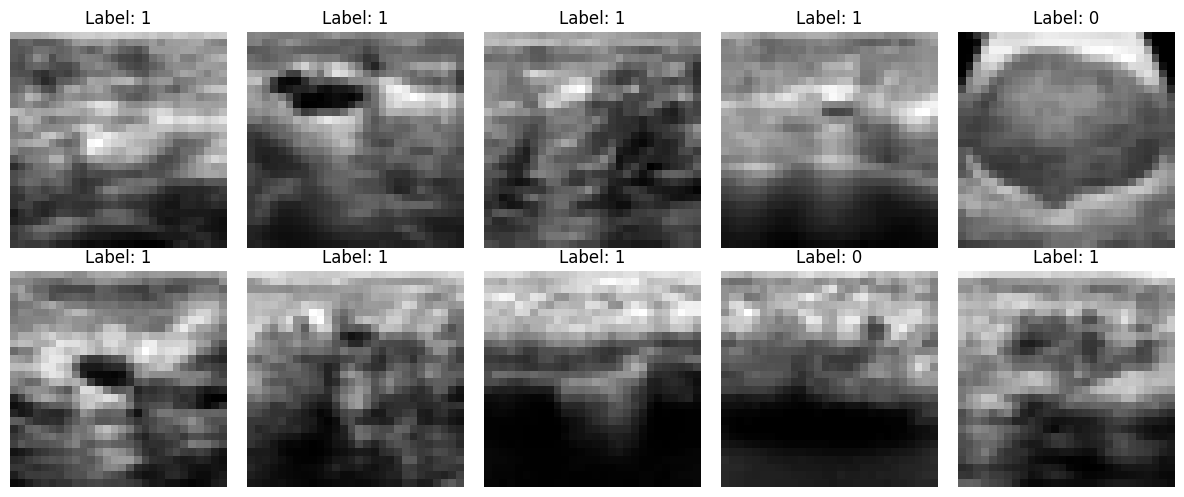

In [9]:
#Visualizing images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(f"Label: {int(label[0])}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [10]:
#Creating Dataloaders

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [15]:
# Get number of classes
num_classes = len(set(
    int(label[0]) for _, label in train_dataset
))

class BreastCancerCNN(nn.Module):

    def __init__(self):
        super(BreastCancerCNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


# Initialize model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BreastCancerCNN().to(device)

print(model)
print("Using device:", device)

BreastCancerCNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)
Using device: cuda


In [16]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer and loss function initialized!")

Optimizer and loss function initialized!


In [17]:
epochs = 15

train_losses = []
val_losses = []
val_accuracies = []

best_val_loss = float('inf')

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.squeeze(1).long().to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_val_loss / len(val_loader)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_breastmnist_cnn.pth")

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/15] Train Loss: 0.6093 | Val Loss: 0.6042 | Val Accuracy: 0.7308
Epoch [2/15] Train Loss: 0.5547 | Val Loss: 0.5909 | Val Accuracy: 0.7308
Epoch [3/15] Train Loss: 0.5751 | Val Loss: 0.5579 | Val Accuracy: 0.7308
Epoch [4/15] Train Loss: 0.5268 | Val Loss: 0.5413 | Val Accuracy: 0.7564
Epoch [5/15] Train Loss: 0.5000 | Val Loss: 0.5265 | Val Accuracy: 0.7436
Epoch [6/15] Train Loss: 0.4875 | Val Loss: 0.5411 | Val Accuracy: 0.7308
Epoch [7/15] Train Loss: 0.5208 | Val Loss: 0.5109 | Val Accuracy: 0.7692
Epoch [8/15] Train Loss: 0.5044 | Val Loss: 0.5054 | Val Accuracy: 0.7821
Epoch [9/15] Train Loss: 0.5016 | Val Loss: 0.5022 | Val Accuracy: 0.7692
Epoch [10/15] Train Loss: 0.4836 | Val Loss: 0.4836 | Val Accuracy: 0.7821
Epoch [11/15] Train Loss: 0.4748 | Val Loss: 0.4744 | Val Accuracy: 0.8077
Epoch [12/15] Train Loss: 0.4993 | Val Loss: 0.4758 | Val Accuracy: 0.8333
Epoch [13/15] Train Loss: 0.5140 | Val Loss: 0.4999 | Val Accuracy: 0.7821
Epoch [14/15] Train Loss: 0.5070 |

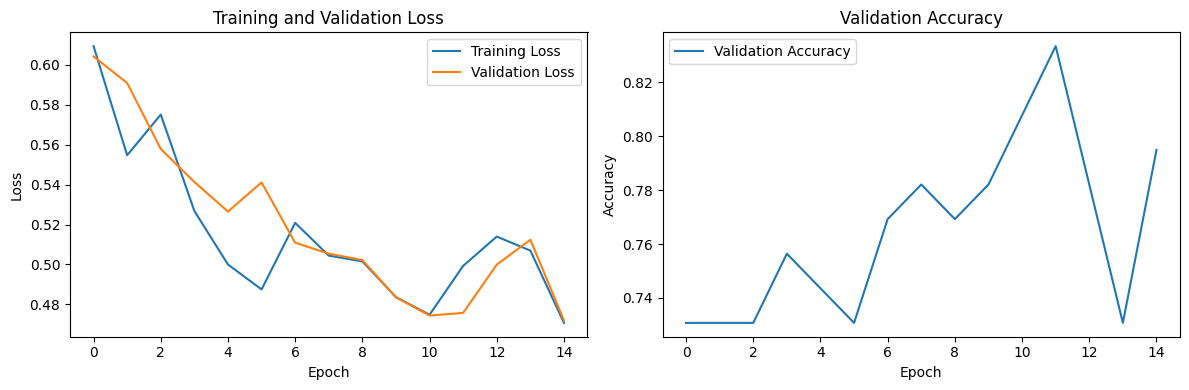

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Load best checkpoint
model.load_state_dict(
    torch.load("best_breastmnist_cnn.pth", map_location=device)
)

model.eval()

y_true = []
y_pred = []
y_probs = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_probs.extend(probabilities[:, 0].cpu().numpy())

# Calculate metrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, pos_label=0))
print("Malignant Recall:", recall_score(y_true, y_pred, pos_label=0))
print("F1 Score:", f1_score(y_true, y_pred, pos_label=0))
print("ROC-AUC:", roc_auc_score(
    np.array(y_true) == 0, y_probs
))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Normal/Benign"],
    zero_division=0
))

Accuracy: 0.7692307692307693
Precision: 1.0
Malignant Recall: 0.14285714285714285
F1 Score: 0.25
ROC-AUC: 0.8191311612364245

Classification Report:
               precision    recall  f1-score   support

    Malignant       1.00      0.14      0.25        42
Normal/Benign       0.76      1.00      0.86       114

     accuracy                           0.77       156
    macro avg       0.88      0.57      0.56       156
 weighted avg       0.82      0.77      0.70       156



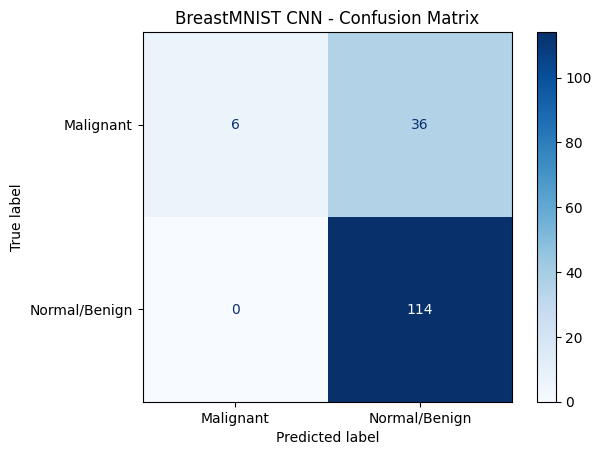

In [20]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Normal/Benign"]
)

disp.plot(cmap="Blues")
plt.title("BreastMNIST CNN - Confusion Matrix")
plt.show()

In [21]:
# Calculate class frequencies in training data
train_labels = [int(label[0]) for _, label in train_dataset]

class_counts = np.bincount(train_labels)

print("Class counts:", class_counts)
print("Class 0: Malignant")
print("Class 1: Normal/Benign")

# Calculate inverse-frequency weights
class_weights = len(train_labels) / (2 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:", class_weights)

Class counts: [147 399]
Class 0: Malignant
Class 1: Normal/Benign
Class weights: tensor([1.8571, 0.6842], device='cuda:0')


In [22]:
# Initialize a fresh model
model = BreastCancerCNN().to(device)

# Weighted loss function
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model reinitialized with class-weighted loss!")

Model reinitialized with class-weighted loss!


In [23]:
epochs = 20

best_val_recall = -1
best_val_loss = float('inf')

train_losses = []
val_losses = []
val_recalls = []

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()

    val_loss = 0
    y_val_true = []
    y_val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.squeeze(1).long().to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            y_val_true.extend(labels.cpu().numpy())
            y_val_pred.extend(predictions.cpu().numpy())

    val_loss /= len(val_loader)

    # Malignant recall (class 0)
    val_recall = recall_score(
        y_val_true,
        y_val_pred,
        pos_label=0,
        zero_division=0
    )

    val_losses.append(val_loss)
    val_recalls.append(val_recall)

    # Save best model using malignant recall
    if (val_recall > best_val_recall or
        (val_recall == best_val_recall and val_loss < best_val_loss)):

        best_val_recall = val_recall
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_breastmnist_cnn.pth"
        )

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Malignant Recall: {val_recall:.4f}"
    )

Epoch [1/20] Train Loss: 0.6957 | Val Loss: 0.6857 | Malignant Recall: 0.6190
Epoch [2/20] Train Loss: 0.6865 | Val Loss: 0.6778 | Malignant Recall: 0.2381
Epoch [3/20] Train Loss: 0.6821 | Val Loss: 0.6492 | Malignant Recall: 0.8095
Epoch [4/20] Train Loss: 0.6672 | Val Loss: 0.6190 | Malignant Recall: 0.6190
Epoch [5/20] Train Loss: 0.6133 | Val Loss: 0.6199 | Malignant Recall: 0.6190
Epoch [6/20] Train Loss: 0.6139 | Val Loss: 0.5796 | Malignant Recall: 0.8571
Epoch [7/20] Train Loss: 0.6001 | Val Loss: 0.5729 | Malignant Recall: 0.6667
Epoch [8/20] Train Loss: 0.5863 | Val Loss: 0.5758 | Malignant Recall: 0.6190
Epoch [9/20] Train Loss: 0.5782 | Val Loss: 0.5449 | Malignant Recall: 0.8571
Epoch [10/20] Train Loss: 0.6263 | Val Loss: 0.5397 | Malignant Recall: 0.6667
Epoch [11/20] Train Loss: 0.5965 | Val Loss: 0.5804 | Malignant Recall: 0.6667
Epoch [12/20] Train Loss: 0.5683 | Val Loss: 0.5346 | Malignant Recall: 0.7143
Epoch [13/20] Train Loss: 0.5781 | Val Loss: 0.5202 | Maligna

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load best model
model.load_state_dict(
    torch.load("best_breastmnist_cnn.pth", map_location=device)
)

model.eval()

y_true = []
y_pred = []
y_probs = []

# Predictions
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.squeeze(1).long().to(device)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

        # Probability of malignant class (label 0)
        y_probs.extend(probabilities[:, 0].cpu().numpy())


# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, pos_label=0, zero_division=0
)

malignant_recall = recall_score(
    y_true, y_pred, pos_label=0, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, pos_label=0, zero_division=0
)

roc_auc = roc_auc_score(
    np.array(y_true) == 0,
    y_probs
)


# Display results
print("===== BREASTMNIST CNN EVALUATION =====")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Malignant Precision:{precision:.4f}")
print(f"Malignant Recall:   {malignant_recall:.4f}")
print(f"Malignant F1 Score: {f1:.4f}")
print(f"ROC-AUC:            {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Malignant", "Normal/Benign"],
    zero_division=0
))

===== BREASTMNIST CNN EVALUATION =====
Accuracy:           0.6859
Malignant Precision:0.4521
Malignant Recall:   0.7857
Malignant F1 Score: 0.5739
ROC-AUC:            0.8003

Classification Report:
               precision    recall  f1-score   support

    Malignant       0.45      0.79      0.57        42
Normal/Benign       0.89      0.65      0.75       114

     accuracy                           0.69       156
    macro avg       0.67      0.72      0.66       156
 weighted avg       0.77      0.69      0.70       156



In [25]:
torch.save(
    model.state_dict(),
    "breastmnist_cnn_final.pth"
)

print("Final CNN model saved successfully!")

Final CNN model saved successfully!


In [26]:
from google.colab import files

files.download("breastmnist_cnn_final.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>